# Maintain Multi-Velocity Stepped Speed Ramp

This notebook loads a checkpoint trained with `maintain_multi_velocity` task transfer
and generates a rollout where the target speed steps from 0.1 to 1.5 m/s in increments
of 0.1, holding each speed for 3 seconds.

- Video rendering of the stepped speed rollout
- Target speed vs actual forward velocity over time
- Per-speed tracking analysis
- Reward component breakdown

## Imports & Environment Setup

In [1]:
%load_ext autoreload
%autoreload 2

import os

os.environ["XLA_PYTHON_CLIENT_PREALLOCATE"] = "false"
os.environ["PYOPENGL_PLATFORM"] = "egl"
os.environ["MUJOCO_GL"] = "egl"

import functools
from pathlib import Path

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import mediapy as media
import mujoco
import numpy as np
from brax.training.acme import running_statistics, specs
from brax.training.agents.ppo import networks as ppo_networks

from scamper.environment.rodent import consts as rodent_consts
from scamper.environment.rodent import maintain_multi_velocity

from scamper.agent.task_transfer.maintain_multi_velocity.checkpoint_utils import (
    load_prior_checkpoint,
    load_task_transfer_metadata,
    load_task_transfer_brax_params,
    make_decoder_inference_fn,
    make_prior_inference_fn,
)
from scamper.agent.task_transfer.maintain_multi_velocity.wrappers import (
    DecoderHighLevelWrapper,
    FlatObsWrapper,
    PriorDecoderHighLevelWrapper,
)
from scamper.agent.task_transfer.maintain_multi_velocity.scratch_networks import (
    make_scratch_ppo_networks,
)
from scamper.agent.task_transfer.maintain_multi_velocity.logging import (
    set_eval_target_speed,
)

E0427 10:04:13.394519 2161668 numa_hwloc.cc:121] Call to hwloc_set_cpubind() failed: Invalid argument [22]
E0427 10:04:13.395185 2161669 numa_hwloc.cc:121] Call to hwloc_set_cpubind() failed: Invalid argument [22]
E0427 10:04:13.395259 2161670 numa_hwloc.cc:121] Call to hwloc_set_cpubind() failed: Invalid argument [22]


## Configuration

Set the checkpoint path and speed ramp parameters here.

In [2]:
# Checkpoint path - UPDATE THIS to your maintain_multi_velocity checkpoint
CHECKPOINT_PATH = "/home/mila/a/aidan.sirbu/SCAMPER/scratch/maintain_multi_velocity_checkpoints/260425_115716_058417"
CHECKPOINT_STEP = 37  # None = latest step

# Speed ramp parameters
SPEEDS = np.arange(0.1, 1.25, 0.1)  # 0.1, 0.2, ..., 1.5
HOLD_DURATION = 3.0  # seconds at each speed

# Rollout parameters
SEED = 0

# Rendering parameters
RENDER_CAMERA = "close_profile-rodent"
RENDER_HEIGHT = 720
RENDER_WIDTH = 1280
RENDER_FPS = 50

# Output directory
OUTPUT_DIR = Path("../../data/maintain_multi_velocity_speed_ramp_analysis")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

## Load Checkpoint

Load the maintain_multi_velocity checkpoint and determine the training mode.

In [3]:
# Load metadata to get config and determine mode
ckpt_info = load_task_transfer_metadata(CHECKPOINT_PATH, step=CHECKPOINT_STEP)
config = ckpt_info["config"]
training_metadata = ckpt_info["training_metadata"]
ckpt_step = ckpt_info["step"]

mode = config["mode"]
ckpt_cfg = config["checkpoint_config"]

print(f"Loaded checkpoint at step: {ckpt_step}")
print(f"Training mode: {mode}")
print(f"Training metadata: {training_metadata}")

Loaded checkpoint at step: 37
Training mode: distill
Training metadata: {'completed_timesteps': 569835520, 'eval_step': 37, 'wandb_run_id': 'distill_260425_115716_058417', 'run_id': '260425_115716_058417', 'mode': 'distill'}


In [4]:
# Load frozen networks from the prior checkpoint embedded in the task transfer checkpoint
prior_checkpoint_path = config["checkpoint"]["path"]
prior_checkpoint_step = config["checkpoint"]["step"]

# distill mode loads from a DistillNetwork-prefixed checkpoint;
# decoder_only / prior_decoder load from a PriorNetwork-prefixed checkpoint.
prior_step_prefix = "DistillNetwork" if mode == "distill" else "PriorNetwork"

print(f"Loading frozen networks from prior checkpoint: {prior_checkpoint_path}")
print(f"Step prefix: {prior_step_prefix}")

(
    encoder_params,
    prior_params,
    decoder_params,
    normalizer_params,
    _,
) = load_prior_checkpoint(
    prior_checkpoint_path, prior_checkpoint_step, step_prefix=prior_step_prefix
)

latent_size = ckpt_cfg["network_config"]["intention_size"]
proprio_size = ckpt_cfg["network_config"]["obs_sizes"]["proprioception"]
action_size = ckpt_cfg["network_config"]["action_size"]

print(f"Latent size: {latent_size}")
print(f"Proprio size: {proprio_size}")
print(f"Action size: {action_size}")

Loading frozen networks from prior checkpoint: /home/mila/a/aidan.sirbu/SCAMPER/scratch/distill_checkpoints/260327_134740_079934
Step prefix: DistillNetwork
Latent size: 16
Proprio size: 277
Action size: 38


## Create Environment

Create the maintain_multi_velocity environment with the appropriate wrapper based on training mode.

In [5]:
# Create environment config from checkpoint
env_cfg = maintain_multi_velocity.default_config()

# Set XML variant
xml_variant = config["env"].get("xml_variant", "full-collisions")
if xml_variant == "limited-collisions":
    env_cfg.walker_xml_path = rodent_consts.RODENT_XML_PATH
elif xml_variant == "full-collisions":
    env_cfg.walker_xml_path = rodent_consts.RODENT_FULL_COLLISION_XML
elif xml_variant == "no-tail-collisions":
    env_cfg.walker_xml_path = rodent_consts.RODENT_NO_TAIL_COLLISION_XML
else:
    raise ValueError(f"Unknown xml_variant: {xml_variant}")

env_cfg.mujoco_impl = config["env"].get("mujoco_impl", "jax")
env_cfg.ctrl_dt = ckpt_cfg["env_config"]["ctrl_dt"]
env_cfg.init_z = config["env"]["init_z"]
env_cfg.min_velocity = config["env"]["min_velocity"]
env_cfg.max_velocity = config["env"]["max_velocity"]

# Set reward terms from config
reward_weights = config["env"]["reward_weights"]
env_cfg.reward_terms = {
    "forward_velocity": {"weight": reward_weights["forward_velocity"]},
    "lateral_velocity": {"weight": reward_weights["lateral_velocity"]},
    "angular_velocity_z": {"weight": reward_weights["angular_velocity_z"]},
}
if "control_diff_cost" in reward_weights:
    env_cfg.reward_terms["control_diff_cost"] = {
        "weight": reward_weights["control_diff_cost"]
    }

# Set actuator type based on mode
if mode == "scratch":
    env_cfg.torque_actuators = config.get("scratch", {}).get("torque_actuators", True)
else:
    env_cfg.torque_actuators = True

print(f"XML variant: {xml_variant}")
print(f"MuJoCo impl: {env_cfg.mujoco_impl}")
print(f"ctrl_dt: {env_cfg.ctrl_dt}")
print(f"Velocity range: [{env_cfg.min_velocity}, {env_cfg.max_velocity}]")

XML variant: no-tail-collisions
MuJoCo impl: warp
ctrl_dt: 0.01
Velocity range: [0.1, 1.5]


In [6]:
# Create decoder inference function
decoder_fn = make_decoder_inference_fn(decoder_params, normalizer_params, ckpt_cfg)

# Create base environment
base_env = maintain_multi_velocity.MaintainMultiVelocity(config=env_cfg)

# Wrap based on mode
if mode == "decoder_only":
    env = DecoderHighLevelWrapper(base_env, decoder_fn, latent_size, proprio_size)
elif mode == "scratch":
    env = FlatObsWrapper(base_env)
elif mode in ("prior_decoder", "distill"):
    # distill mode mirrors prior_decoder at inference time but reads its
    # deterministic_prior / noise_logvar from config["distill"].
    mode_cfg = config["distill"] if mode == "distill" else config["prior_decoder"]
    prior_fn = make_prior_inference_fn(prior_params, normalizer_params, ckpt_cfg)
    env = PriorDecoderHighLevelWrapper(
        base_env,
        prior_fn,
        decoder_fn,
        latent_size,
        proprio_size,
        deterministic_prior=mode_cfg["deterministic_prior"],
        noise_logvar=mode_cfg["noise_logvar"],
    )
else:
    raise ValueError(f"Unknown mode: {mode}")

print(f"Created wrapped environment for mode: {mode}")
print(f"Action size (policy outputs): {env.action_size}")

Warp 1.11.0 initialized:
   CUDA Toolkit 12.9, Driver 13.0
   Devices:
     "cpu"      : "x86_64"
     "cuda:0"   : "NVIDIA A100-SXM4-80GB" (79 GiB, sm_80, mempool enabled)
   Kernel cache:
     /home/mila/a/aidan.sirbu/.cache/warp/1.11.0
Warp DeprecationWarning: The symbol `warp.types.warp_type_to_np_dtype` will soon be removed from the public API. It can still be accessed from `warp._src.types.warp_type_to_np_dtype` but might be changed or removed without notice.
Created wrapped environment for mode: distill
Action size (policy outputs): 16


## Load Policy Parameters and Create Inference Function

In [7]:
# Create JIT-compiled reset and step functions
jit_reset = jax.jit(env.reset)
jit_step = jax.jit(env.step)

# Get observation shape from a reset
rng = jax.random.PRNGKey(0)
start_state = jit_reset(rng)
obs_size = start_state.obs.shape[-1]

print(f"Observation size: {obs_size}")

Module mujoco.mjx.third_party.mujoco_warp._src.smooth e142b0f load on device 'cuda:0' took 8.63 ms  (cached)
Module mujoco.mjx.third_party.mujoco_warp._src.collision_driver de6dc98 load on device 'cuda:0' took 1.99 ms  (cached)
Module _nxn_broadphase__locals__kernel_8c837afb 8c837af load on device 'cuda:0' took 1.94 ms  (cached)
Module _primitive_narrowphase__locals__primitive_narrowphase_3a95495c 42367f3 load on device 'cuda:0' took 2.41 ms  (cached)
Module mujoco.mjx.third_party.mujoco_warp._src.constraint 51cd7b3 load on device 'cuda:0' took 4.88 ms  (cached)
Module _actuator_velocity__locals__actuator_velocity_0d638ad6 1622c88 load on device 'cuda:0' took 2.12 ms  (cached)
Module _tendon_velocity__locals__tendon_velocity_72b33c1e d7da02d load on device 'cuda:0' took 1.97 ms  (cached)
Module mujoco.mjx.third_party.mujoco_warp._src.passive 6808b5e load on device 'cuda:0' took 2.67 ms  (cached)
Module mujoco.mjx.third_party.mujoco_warp._src.sensor ca6ca3f load on device 'cuda:0' took 

E0427 10:04:25.448580 2161675 slow_operation_alarm.cc:73] Constant folding an instruction is taking > 1s:

  %reduce_sum.99 = s32[] reduce(%constant.168, %constant.255), dimensions={0}, to_apply=%region_1.8, metadata={op_name="jit(reset)/reduce_sum" stack_frame_id=15}

This isn't necessarily a bug; constant-folding is inherently a trade-off between compilation time and speed at runtime. XLA has some guards that attempt to keep constant folding from taking too long, but fundamentally you'll always be able to come up with an input program that takes a long time.

If you'd like to file a bug, run with envvar XLA_FLAGS=--xla_dump_to=/tmp/foo and attach the results.
E0427 10:04:35.790791 2161556 slow_operation_alarm.cc:140] The operation took 11.342387265s
Constant folding an instruction is taking > 1s:

  %reduce_sum.99 = s32[] reduce(%constant.168, %constant.255), dimensions={0}, to_apply=%region_1.8, metadata={op_name="jit(reset)/reduce_sum" stack_frame_id=15}

This isn't necessarily a b

Observation size: 332


In [8]:
# Create network factory and build abstract params for loading
normalize = running_statistics.normalize
policy_action_size = env.action_size

if mode == "scratch":
    task_obs_size = obs_size - proprio_size
    decoder_hidden_layer_sizes = tuple(
        ckpt_cfg["network_config"]["decoder_layer_sizes"]
    )

    def network_factory(*args, **kwargs):
        return make_scratch_ppo_networks(
            task_obs_size=task_obs_size,
            proprio_size=proprio_size,
            action_size=action_size,
            latent_size=latent_size,
            policy_hidden_layer_sizes=tuple(config["network"]["policy_layers"]),
            decoder_hidden_layer_sizes=decoder_hidden_layer_sizes,
            value_hidden_layer_sizes=tuple(config["network"]["value_layers"]),
        )

    dummy_net = network_factory()
    key_p, key_v = jax.random.split(jax.random.PRNGKey(0))
    dummy_normalizer = running_statistics.init_state(
        specs.Array(start_state.obs.shape[-1:], jnp.dtype("float32"))
    )
    dummy_policy = dummy_net.policy_network.init(key_p)
    dummy_value = dummy_net.value_network.init(key_v)
else:
    network_factory = functools.partial(
        ppo_networks.make_ppo_networks,
        policy_hidden_layer_sizes=tuple(config["network"]["policy_layers"]),
        value_hidden_layer_sizes=tuple(config["network"]["value_layers"]),
    )

    dummy_net = network_factory(
        obs_size, policy_action_size, preprocess_observations_fn=normalize
    )
    key_p, key_v = jax.random.split(jax.random.PRNGKey(0))
    dummy_normalizer = running_statistics.init_state(
        specs.Array(start_state.obs.shape[-1:], jnp.dtype("float32"))
    )
    dummy_policy = dummy_net.policy_network.init(key_p)
    dummy_value = dummy_net.value_network.init(key_v)

abstract_brax_params = (dummy_normalizer, dummy_policy, dummy_value)

# Load trained parameters
brax_params = load_task_transfer_brax_params(
    CHECKPOINT_PATH, abstract_brax_params, step=ckpt_step
)

print("Loaded policy parameters")

Loaded policy parameters


In [9]:
# Create inference function
if mode == "scratch":
    ppo_network = network_factory()
    policy_network = ppo_network.policy_network
    parametric_action_distribution = ppo_network.parametric_action_distribution

    def inference_fn(params, observations, key_sample):
        del key_sample  # Deterministic
        param_subset = (params[0], params[1])
        logits = policy_network.apply(*param_subset, observations)
        action = parametric_action_distribution.mode(logits)
        return action, {}

else:
    ppo_network = network_factory(
        obs_size, policy_action_size, preprocess_observations_fn=normalize
    )
    policy_network = ppo_network.policy_network
    parametric_action_distribution = ppo_network.parametric_action_distribution

    def inference_fn(params, observations, key_sample):
        del key_sample  # Deterministic
        param_subset = (params[0], params[1])
        logits = policy_network.apply(*param_subset, observations)
        action = parametric_action_distribution.mode(logits)
        return action, {}


jit_inference_fn = jax.jit(inference_fn)
print("Created inference function")

Created inference function


## Compute Rollout Parameters

In [10]:
ctrl_dt = ckpt_cfg["env_config"]["ctrl_dt"]
STEPS_PER_SPEED = int(HOLD_DURATION / ctrl_dt)
EPISODE_LENGTH = len(SPEEDS) * STEPS_PER_SPEED

print(f"ctrl_dt: {ctrl_dt} s")
print(f"Steps per speed: {STEPS_PER_SPEED} ({HOLD_DURATION} s)")
print(f"Number of speeds: {len(SPEEDS)} ({SPEEDS[0]:.1f} to {SPEEDS[-1]:.1f} m/s)")
print(
    f"Total episode length: {EPISODE_LENGTH} steps ({EPISODE_LENGTH * ctrl_dt:.1f} s)"
)

# Get torso body index (needed for scan in rollout cell)
unwrapped_env = env
while hasattr(unwrapped_env, "_env") or hasattr(unwrapped_env, "env"):
    if hasattr(unwrapped_env, "_env"):
        unwrapped_env = unwrapped_env._env
    elif hasattr(unwrapped_env, "env"):
        unwrapped_env = unwrapped_env.env

mj_model = unwrapped_env.mj_model
torso_body_id = mujoco.mj_name2id(mj_model, mujoco.mjtObj.mjOBJ_BODY, "torso-rodent")
print(f"Torso body ID: {torso_body_id}")

ctrl_dt: 0.01 s
Steps per speed: 300 (3.0 s)
Number of speeds: 12 (0.1 to 1.2 m/s)
Total episode length: 3600 steps (36.0 s)
Torso body ID: 3


## Generate Rollout with Stepped Speed Ramp

The target speed steps from 0.1 to 1.5 m/s in increments of 0.1, holding each
speed for 3 seconds. At each step, `set_eval_target_speed()` overrides both
`state.info["target_speed"]` and the corresponding element in the flat observation.

In [11]:
rng = jax.random.PRNGKey(SEED)
reset_rng, act_rng = jax.random.split(rng)

state = jit_reset(reset_rng)


# Use jax.lax.scan per speed segment — runs entirely on GPU, no Python-loop sync
def scan_step(carry, _):
    state, act_rng = carry
    _, act_rng = jax.random.split(act_rng)
    action, _ = jit_inference_fn(brax_params, state.obs, act_rng)
    state = jit_step(state, action)
    return (state, act_rng), {
        "xpos_x": state.data.xpos[torso_body_id, 0],
        "reward": state.reward,
        "done": state.done,
        "qpos": state.data.qpos,
        "metrics": state.metrics,
    }


jit_scan_segment = jax.jit(
    lambda state, act_rng: jax.lax.scan(
        scan_step, (state, act_rng), None, length=STEPS_PER_SPEED
    )
)

# Pre-allocate collection lists
all_xpos_x = [float(state.data.xpos[torso_body_id, 0])]
all_rewards = []
all_dones = []
all_qpos = [np.array(state.data.qpos)]
all_metrics = {}
target_speeds = []

print("Generating stepped speed ramp rollout...")

for speed_idx, speed in enumerate(SPEEDS):
    state = set_eval_target_speed(state, float(speed), proprio_size)
    print(f"  Speed {speed:.1f} m/s ({speed_idx + 1}/{len(SPEEDS)})")

    (state, act_rng), seg = jit_scan_segment(state, act_rng)
    seg = jax.device_get(seg)

    all_xpos_x.extend(seg["xpos_x"].tolist())
    all_rewards.extend(seg["reward"].tolist())
    all_dones.extend(seg["done"].tolist())
    all_qpos.extend(list(seg["qpos"]))
    for k, v in seg["metrics"].items():
        all_metrics.setdefault(k, []).extend(v.tolist())
    target_speeds.extend([float(speed)] * STEPS_PER_SPEED)

    state = set_eval_target_speed(state, float(speed), proprio_size)

target_speeds = np.array(target_speeds)
all_xpos_x = np.array(all_xpos_x)
all_rewards = np.array(all_rewards)
all_dones = np.array(all_dones)
all_metrics = {k: np.array(v) for k, v in all_metrics.items()}

print(f"Rollout complete! {len(all_xpos_x)} steps collected.")

Generating stepped speed ramp rollout...
  Speed 0.1 m/s (1/12)
Module mujoco.mjx.warp.ffi edde159 load on device 'cuda:0' took 3.11 ms  (cached)
  Speed 0.2 m/s (2/12)
  Speed 0.3 m/s (3/12)
  Speed 0.4 m/s (4/12)
  Speed 0.5 m/s (5/12)
  Speed 0.6 m/s (6/12)
  Speed 0.7 m/s (7/12)
  Speed 0.8 m/s (8/12)
  Speed 0.9 m/s (9/12)
  Speed 1.0 m/s (10/12)
  Speed 1.1 m/s (11/12)
  Speed 1.2 m/s (12/12)
Rollout complete! 3601 steps collected.


## Extract Actual Velocity

In [12]:
# Compute forward velocity via finite differences of pre-extracted xpos
actual_velocity = np.diff(all_xpos_x) / ctrl_dt

print(f"Velocity range: [{actual_velocity.min():.3f}, {actual_velocity.max():.3f}] m/s")
print(f"Mean velocity: {actual_velocity.mean():.3f} m/s")

Velocity range: [-0.022, 2.778] m/s
Mean velocity: 0.534 m/s


## Render Video

In [13]:
import cv2

print(f"Rendering video with camera '{RENDER_CAMERA}'...")

# Make a copy of the model with extended floor and lighting for rendering
render_model = mj_model.__copy__()

# Extend floor texture extent so the rodent doesn't walk off the visible checkerboard
floor_id = mujoco.mj_name2id(render_model, mujoco.mjtObj.mjOBJ_GEOM, "floor")
render_model.geom_size[floor_id] = [100.0, 100.0, 0.005]

# Raise the fixed light and widen its cone so the full arena is lit
# Disable its shadow to avoid artefacts under the rodent
render_model.light_pos[0] = [0.0, 0.0, 50.0]
render_model.light_cutoff[0] = 90.0
render_model.light_castshadow[0] = 0

renderer = mujoco.Renderer(render_model, height=RENDER_HEIGHT, width=RENDER_WIDTH)
camera_id = mujoco.mj_name2id(render_model, mujoco.mjtObj.mjOBJ_CAMERA, RENDER_CAMERA)
mj_data = mujoco.MjData(render_model)

frames = []
for i, qpos in enumerate(all_qpos):
    mj_data.qpos[:] = qpos
    mujoco.mj_forward(render_model, mj_data)
    renderer.update_scene(mj_data, camera=camera_id)
    frame = renderer.render().copy()

    # Overlay target and actual speed text
    if i == 0:
        target_text = f"Target: {target_speeds[0]:.1f} m/s"
        actual_text = "Actual: -- m/s"
    else:
        target_text = f"Target: {target_speeds[i - 1]:.1f} m/s"
        actual_text = f"Actual: {actual_velocity[i - 1]:.2f} m/s"

    cv2.putText(
        frame,
        target_text,
        (10, 30),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.7,
        (255, 255, 255),
        2,
        cv2.LINE_AA,
    )
    cv2.putText(
        frame,
        actual_text,
        (10, 60),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.7,
        (255, 255, 255),
        2,
        cv2.LINE_AA,
    )

    frames.append(frame)

renderer.close()
media.show_video(frames, fps=RENDER_FPS)

Rendering video with camera 'close_profile-rodent'...


This browser does not support the video tag.


## Speed Ramp Analysis

Plot the stepped target speed alongside the actual forward velocity.

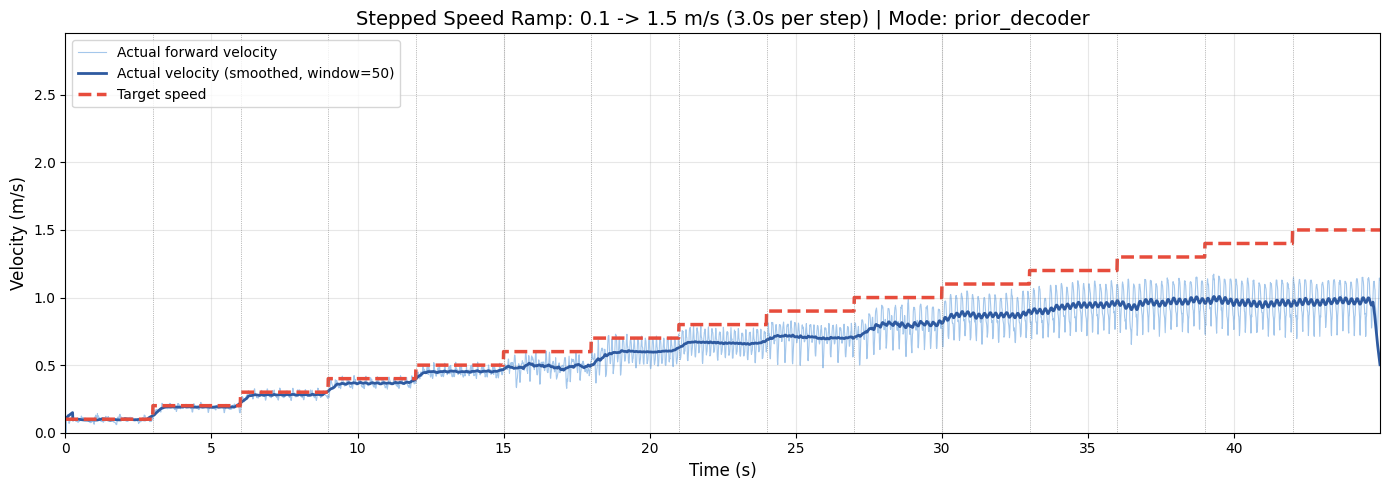

In [ ]:
# Time axis
num_steps = len(actual_velocity)
time_sec = np.arange(num_steps) * ctrl_dt

fig, ax = plt.subplots(figsize=(14, 5))

# Plot actual velocity
ax.plot(
    time_sec,
    actual_velocity,
    color="#4A90D9",
    linewidth=0.8,
    alpha=0.5,
    label="Actual forward velocity",
)

# Smoothed actual velocity
window = min(50, num_steps // 20)
if window > 1:
    smoothed_velocity = np.convolve(
        actual_velocity, np.ones(window) / window, mode="same"
    )
    ax.plot(
        time_sec,
        smoothed_velocity,
        color="#2E5AA0",
        linewidth=2.0,
        label=f"Actual velocity (smoothed, window={window})",
    )

# Plot target speed staircase
ax.plot(
    time_sec,
    target_speeds,
    color="#E74C3C",
    linewidth=2.5,
    linestyle="--",
    label="Target speed",
)

# Vertical lines at speed transitions
for i in range(1, len(SPEEDS)):
    t = i * STEPS_PER_SPEED * ctrl_dt
    ax.axvline(x=t, color="gray", linewidth=0.5, linestyle=":")

ax.set_xlabel("Time (s)", fontsize=12)
ax.set_ylabel("Velocity (m/s)", fontsize=12)
ax.set_title(
    f"Stepped Speed Ramp: {SPEEDS[0]:.1f} -> {SPEEDS[-1]:.1f} m/s "
    f"({HOLD_DURATION}s per step) | Mode: {mode}",
    fontsize=14,
)
ax.legend(fontsize=10, loc="upper left")
ax.grid(True, alpha=0.3)
ax.set_xlim(0, time_sec[-1])
ax.set_ylim(bottom=0)

plt.tight_layout()
plt.show()

## Tracking Error and Reward

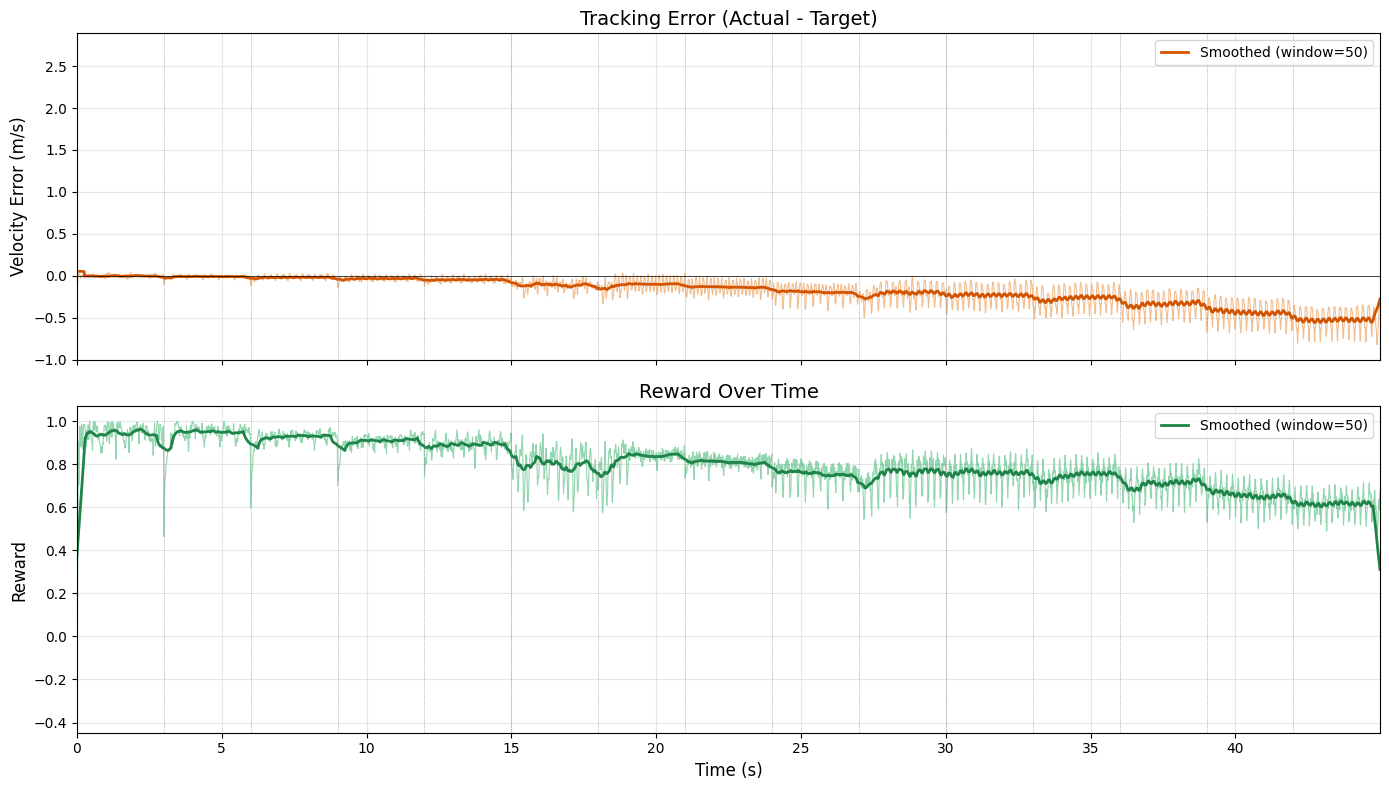

In [ ]:
tracking_error = actual_velocity - target_speeds
rewards = all_rewards

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

# Top: Tracking error
axes[0].plot(time_sec, tracking_error, color="#E67E22", linewidth=0.8, alpha=0.5)
if window > 1:
    smoothed_error = np.convolve(tracking_error, np.ones(window) / window, mode="same")
    axes[0].plot(
        time_sec,
        smoothed_error,
        color="#D35400",
        linewidth=2.0,
        label=f"Smoothed (window={window})",
    )
axes[0].axhline(y=0, color="k", linewidth=0.5, linestyle="-")
for i in range(1, len(SPEEDS)):
    t = i * STEPS_PER_SPEED * ctrl_dt
    axes[0].axvline(x=t, color="gray", linewidth=0.5, linestyle=":")
axes[0].set_ylabel("Velocity Error (m/s)", fontsize=12)
axes[0].set_title("Tracking Error (Actual - Target)", fontsize=14)
axes[0].legend(fontsize=10)
axes[0].grid(True, alpha=0.3)

# Bottom: Reward over time
axes[1].plot(time_sec, rewards, color="#27AE60", linewidth=0.8, alpha=0.5)
if window > 1:
    smoothed_rewards = np.convolve(rewards, np.ones(window) / window, mode="same")
    axes[1].plot(
        time_sec,
        smoothed_rewards,
        color="#1E8449",
        linewidth=2.0,
        label=f"Smoothed (window={window})",
    )
for i in range(1, len(SPEEDS)):
    t = i * STEPS_PER_SPEED * ctrl_dt
    axes[1].axvline(x=t, color="gray", linewidth=0.5, linestyle=":")
axes[1].set_xlabel("Time (s)", fontsize=12)
axes[1].set_ylabel("Reward", fontsize=12)
axes[1].set_title("Reward Over Time", fontsize=14)
axes[1].legend(fontsize=10)
axes[1].grid(True, alpha=0.3)
axes[1].set_xlim(0, time_sec[-1])

plt.tight_layout()
plt.show()

## Reward Component Breakdown

Reward components: ['rewards/angular_velocity_z', 'rewards/control_diff_cost', 'rewards/forward_velocity', 'rewards/lateral_velocity']


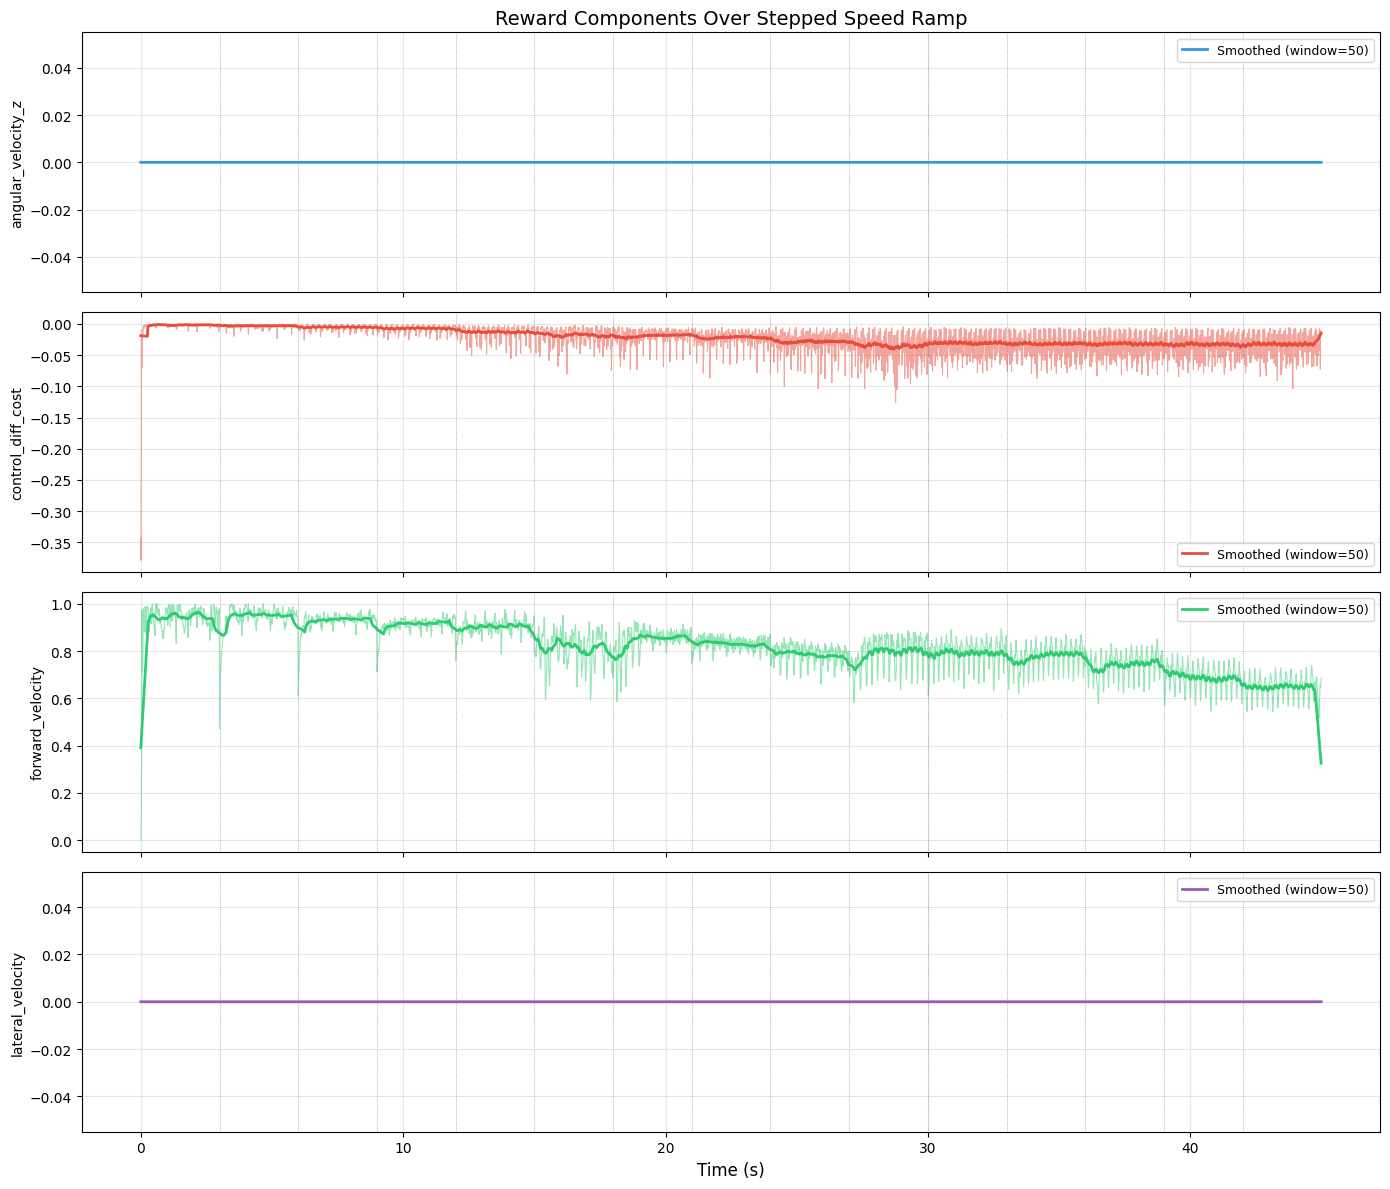

In [ ]:
# Extract reward components from pre-collected metrics
reward_keys = sorted([k for k in all_metrics.keys() if k.startswith("rewards/")])
print(f"Reward components: {reward_keys}")

fig, axes = plt.subplots(
    len(reward_keys), 1, figsize=(14, 3 * len(reward_keys)), sharex=True
)
if len(reward_keys) == 1:
    axes = [axes]

colors = ["#3498DB", "#E74C3C", "#2ECC71", "#9B59B6", "#F39C12"]

for idx, key in enumerate(reward_keys):
    values = all_metrics[key]
    ax = axes[idx]
    ax.plot(time_sec, values, color=colors[idx % len(colors)], linewidth=0.8, alpha=0.5)
    if window > 1:
        smoothed = np.convolve(values, np.ones(window) / window, mode="same")
        ax.plot(
            time_sec,
            smoothed,
            color=colors[idx % len(colors)],
            linewidth=2.0,
            label=f"Smoothed (window={window})",
        )
    for i in range(1, len(SPEEDS)):
        t = i * STEPS_PER_SPEED * ctrl_dt
        ax.axvline(x=t, color="gray", linewidth=0.5, linestyle=":")
    ax.set_ylabel(key.replace("rewards/", ""), fontsize=10)
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=9)

axes[-1].set_xlabel("Time (s)", fontsize=12)
axes[0].set_title("Reward Components Over Stepped Speed Ramp", fontsize=14)

plt.tight_layout()
plt.show()

## Per-Speed Summary Table

In [17]:
print(
    f"{'Speed':>7s}  {'Mean Vel':>9s}  {'Std Vel':>9s}  "
    f"{'Mean Err':>9s}  {'MAE':>9s}  {'Mean Rwd':>9s}"
)
print("-" * 65)

for speed_idx, speed in enumerate(SPEEDS):
    start = speed_idx * STEPS_PER_SPEED
    end = (speed_idx + 1) * STEPS_PER_SPEED

    seg_vel = actual_velocity[start:end]
    seg_err = tracking_error[start:end]
    seg_rwd = rewards[start:end]

    print(
        f"{speed:7.1f}  {seg_vel.mean():9.4f}  {seg_vel.std():9.4f}  "
        f"{seg_err.mean():9.4f}  {np.abs(seg_err).mean():9.4f}  {seg_rwd.mean():9.4f}"
    )

  Speed   Mean Vel    Std Vel   Mean Err        MAE   Mean Rwd
-----------------------------------------------------------------
    0.1     0.1058     0.1574     0.0058     0.0217     0.9273
    0.2     0.1876     0.0173    -0.0124     0.0155     0.9376
    0.3     0.2779     0.0222    -0.0221     0.0263     0.9206
    0.4     0.3643     0.0261    -0.0357     0.0376     0.9033
    0.5     0.4505     0.0271    -0.0495     0.0504     0.8881
    0.6     0.4883     0.0531    -0.1117     0.1117     0.7952
    0.7     0.5900     0.0787    -0.1100     0.1118     0.8254
    0.8     0.6636     0.0716    -0.1364     0.1364     0.8081
    0.9     0.7048     0.0824    -0.1952     0.1952     0.7557
    1.0     0.7892     0.1011    -0.2108     0.2108     0.7537
    1.1     0.8699     0.1107    -0.2301     0.2301     0.7594
    1.2     0.9293     0.1173    -0.2707     0.2707     0.7432
    1.3     0.9629     0.1220    -0.3371     0.3371     0.7093
    1.4     0.9619     0.1254    -0.4381     0.4381 

## Summary Statistics

In [18]:
print("=" * 60)
print("Stepped Speed Ramp Rollout Summary")
print("=" * 60)
print(f"\nCheckpoint: {CHECKPOINT_PATH}")
print(f"Step: {ckpt_step}")
print(f"Mode: {mode}")
print(
    f"Speed ramp: {SPEEDS[0]:.1f} -> {SPEEDS[-1]:.1f} m/s "
    f"(steps of 0.1, {HOLD_DURATION}s each)"
)
print(f"Total duration: {EPISODE_LENGTH * ctrl_dt:.1f} s ({EPISODE_LENGTH} steps)")

print(f"\nVelocity Statistics:")
print(f"  Mean actual velocity: {actual_velocity.mean():.4f} m/s")
print(f"  Std actual velocity:  {actual_velocity.std():.4f} m/s")
print(f"  Min actual velocity:  {actual_velocity.min():.4f} m/s")
print(f"  Max actual velocity:  {actual_velocity.max():.4f} m/s")

print(f"\nTracking Error Statistics:")
print(f"  Mean absolute error:  {np.abs(tracking_error).mean():.4f} m/s")
print(f"  RMS error:            {np.sqrt(np.mean(tracking_error**2)):.4f} m/s")

print(f"\nReward Statistics:")
print(f"  Mean reward: {rewards.mean():.4f}")
print(f"  Total reward: {rewards.sum():.2f}")

# Check if rodent fell
fall_step = np.argmax(all_dones > 0) if np.any(all_dones > 0) else None
if fall_step is not None:
    fall_speed = target_speeds[fall_step]
    fall_time = fall_step * ctrl_dt
    print(f"\n  WARNING: Rodent fell at step {fall_step} ({fall_time:.2f} s)")
    print(f"  Target speed at fall: {fall_speed:.1f} m/s")
else:
    print(f"\n  Rodent did not fall during the entire rollout.")

Stepped Speed Ramp Rollout Summary

Checkpoint: /home/mila/a/aidan.sirbu/SCAMPER/scratch/maintain_multi_velocity_checkpoints/260324_200619_220174
Step: 19
Mode: prior_decoder
Speed ramp: 0.1 -> 1.5 m/s (steps of 0.1, 3.0s each)
Total duration: 45.0 s (4500 steps)

Velocity Statistics:
  Mean actual velocity: 0.6212 m/s
  Std actual velocity:  0.3017 m/s
  Min actual velocity:  -0.0025 m/s
  Max actual velocity:  2.8137 m/s

Tracking Error Statistics:
  Mean absolute error:  0.1814 m/s
  RMS error:            0.2545 m/s

Reward Statistics:
  Mean reward: 0.7997
  Total reward: 3598.70

  Target speed at fall: 0.5 m/s
